In [141]:
import random
import numpy as np
import pandas as pd

# 划分训练集与测试集
from sklearn.model_selection import train_test_split
# 标准化
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
# 优化器
import torch.optim as optim

In [142]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']
plt.rcParams['figure.dpi'] = 150   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

In [143]:
torch.set_num_threads(4)

In [144]:
# 设置随机种子（不含对batch划分的设置）
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [145]:
# 观察数据集都有哪些文件
data = np.load('mnist.npz')
print(data.files)

['x_test', 'x_train', 'y_train', 'y_test']


In [146]:
# 导入数据，并观察数据形状
x_train, x_test, y_train, y_test = data['x_train'], data['x_test'], data['y_train'], data['y_test']
print(f"训练集特征形状: {x_train.shape}")
print(f"训练集标签形状: {y_train.shape}")
print(f"测试集特征形状: {x_test.shape}")
print(f"测试集标签形状: {y_test.shape}")

训练集特征形状: (60000, 28, 28)
训练集标签形状: (60000,)
测试集特征形状: (10000, 28, 28)
测试集标签形状: (10000,)


In [147]:
# 将单条标签数据转变为一维张量
x_train = x_train.reshape((60000, 28 * 28))
x_test = x_test.reshape((10000, 28 * 28))
print(f"训练集特征形状: {x_train.shape}")
print(f"测试集特征形状: {x_test.shape}")

# 数据范围仅[0, 255]，故除以255即可归一化
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

# 另外，torch框架下，无需对无序类别标签作one-hot处理

训练集特征形状: (60000, 784)
测试集特征形状: (10000, 784)


In [148]:
# 将特征、标签等数据，转换为torch中的张量
x_train_tensor = torch.tensor(x_train, dtype = torch.float32)
x_test_tensor = torch.tensor(x_test, dtype = torch.float32)

y_train_tensor = torch.tensor(y_train, dtype = torch.long) # 无序类别标签，类型必须是torch.long
y_test_tensor = torch.tensor(y_test, dtype = torch.long)

In [149]:
# 将全数据集组织起来，以便后面分batch
g = torch.Generator()
g.manual_seed(42) # 为了可复现，为batch划分也设置固定随机种子

batch = 128  # 设置batch大小（训练集、测试集均会用到）
train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
train_dataloader = DataLoader(train_dataset, batch_size=batch, shuffle=True, generator=g)

In [150]:
# 自定义网络结构
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层 512
        self.out = nn.Linear(512, 10) # 隐藏层 512 -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.out(x)  # 直接输出线性结果
        return x

In [151]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

In [152]:
model.train() # 设置为训练模式

epochs = 20
result_history = []

for epoch in range(epochs):
    total_loss = 0.0  # 记录每个epoch的总损失
    batch_count = 0   # 记录该epoch的总batch数

    for batch_x, batch_y in train_dataloader:
        optimizer.zero_grad() # 梯度清零
        preds_y = model(batch_x) # 前向传播
        loss_train = criterion(preds_y, batch_y) # 计算损失
        loss_train.backward() # 反向传播（自动求导 并 累加梯度）
        optimizer.step() # 根据求导计算出的 梯度，更新模型参数

        total_loss += loss_train.item()
        batch_count += 1
    
    result_history.append(total_loss / batch_count) # 记录损失
    
    print(f"训练进度: {epoch+1}/{epochs}, 训练集loss: {total_loss / batch_count:.4f}")

训练进度: 1/20, 训练集loss: 0.2550
训练进度: 2/20, 训练集loss: 0.1078
训练进度: 3/20, 训练集loss: 0.0707
训练进度: 4/20, 训练集loss: 0.0499
训练进度: 5/20, 训练集loss: 0.0367
训练进度: 6/20, 训练集loss: 0.0263
训练进度: 7/20, 训练集loss: 0.0212
训练进度: 8/20, 训练集loss: 0.0148
训练进度: 9/20, 训练集loss: 0.0125
训练进度: 10/20, 训练集loss: 0.0093
训练进度: 11/20, 训练集loss: 0.0074
训练进度: 12/20, 训练集loss: 0.0057
训练进度: 13/20, 训练集loss: 0.0052
训练进度: 14/20, 训练集loss: 0.0042
训练进度: 15/20, 训练集loss: 0.0041
训练进度: 16/20, 训练集loss: 0.0031
训练进度: 17/20, 训练集loss: 0.0031
训练进度: 18/20, 训练集loss: 0.0022
训练进度: 19/20, 训练集loss: 0.0026
训练进度: 20/20, 训练集loss: 0.0016


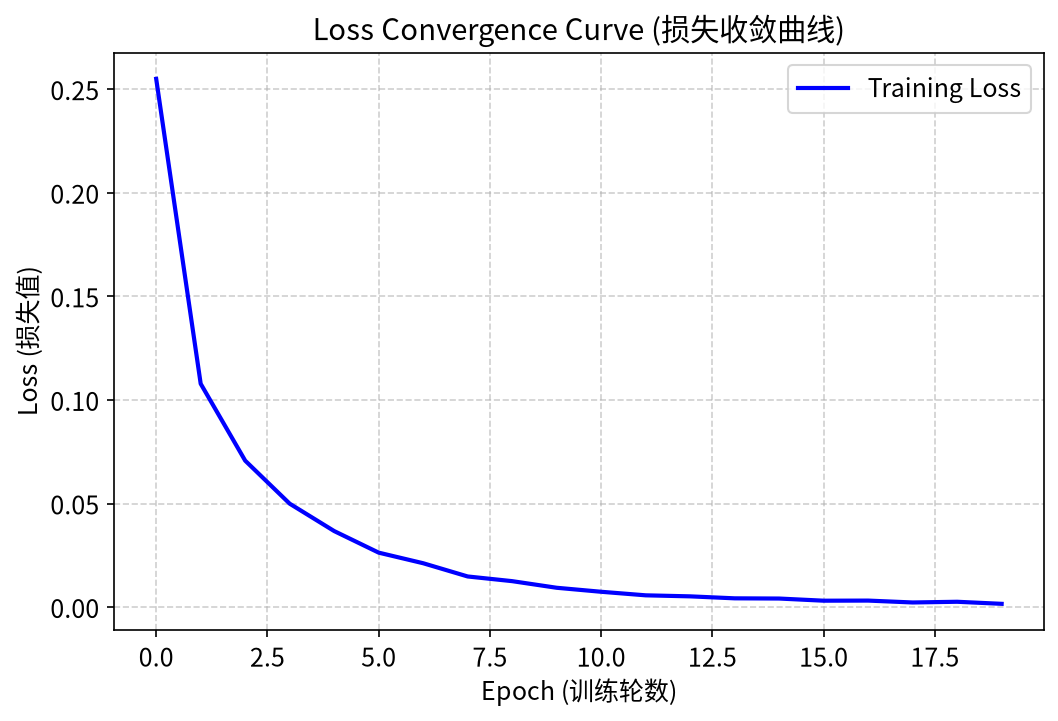

In [153]:
# 绘制loss曲线，查看收敛情况
plt.figure(figsize=(8, 5))  # 设置画布大小，宽8，高5
plt.plot(result_history, label='Training Loss', color='blue', linewidth=2)

# 添加标签
plt.title('Loss Convergence Curve (损失收敛曲线)', fontsize=14)
plt.xlabel('Epoch (训练轮数)', fontsize=12)
plt.ylabel('Loss (损失值)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.6)  # 添加网格线，方便看数值
plt.legend(fontsize=12)  # 显示图例

plt.show()

In [154]:
model.eval() # 将模型切换到测试状态
test_correct = 0
test_total = 0
test_total_loss = 0.0

# 同样分batch进行测试
test_dataset = TensorDataset(x_test_tensor, y_test_tensor)
test_dataloader = DataLoader(test_dataset, batch_size=batch, shuffle=False)

with torch.no_grad(): # 关闭梯度计算，节省内存
    for batch_x, batch_y in test_dataloader:
        test_preds = model(batch_x)
        loss = criterion(test_preds, batch_y)
        test_total_loss += loss.item()
        
        predicted_classes = torch.argmax(test_preds, dim=1)
        test_correct += (predicted_classes == batch_y).sum().item()
        test_total += batch_y.size(0)

avg_test_loss = test_total_loss / len(test_dataloader)  # 计算平均loss
accuracy = test_correct / test_total    # 计算Acc

print(f"测试集平均损失 (Test Loss): {avg_test_loss:.4f}")
print(f"测试集准确率 (Test Accuracy): {accuracy * 100:.2f}%  ({test_correct}/{test_total})")

测试集平均损失 (Test Loss): 0.0814
测试集准确率 (Test Accuracy): 98.31%  (9831/10000)
